<a href="https://colab.research.google.com/github/LauHiapZhi/data-science-project/blob/main/IdsProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [134]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [135]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression, mutual_info_regression
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [136]:
folder = '/content/drive/MyDrive/data science project'

In [137]:
df = pd.read_csv("/content/drive/MyDrive/data science project/donations_state.csv")

In [138]:
df.head()

,date,state,daily,blood_a,blood_b,blood_o,blood_ab,location_centre,location_mobile,type_wholeblood,type_apheresis_platelet,type_apheresis_plasma,type_other,social_civilian,social_student,social_policearmy,donations_new,donations_regular,donations_irregular
0,2006-01-01,Malaysia,525,152,139,194,40,308,217,525,0,0,0,496,18,11,243,277,5
1,2006-01-02,Malaysia,227,53,43,112,19,162,65,217,6,4,0,224,2,1,83,143,1
2,2006-01-03,Malaysia,112,29,21,56,6,112,0,89,10,13,0,105,2,5,8,101,3
3,2006-01-04,Malaysia,391,92,98,165,36,145,246,371,4,16,0,316,71,4,286,102,3
4,2006-01-05,Malaysia,582,149,198,193,42,371,211,548,17,17,0,555,19,8,328,250,4


In [139]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 106484 entries, 0 to 106483
Data columns (total 19 columns):
 #   Column                   Non-Null Count   Dtype 
---  ------                   --------------   ----- 
 0   date                     106484 non-null  object
 1   state                    106484 non-null  object
 2   daily                    106484 non-null  int64 
 3   blood_a                  106484 non-null  int64 
 4   blood_b                  106484 non-null  int64 
 5   blood_o                  106484 non-null  int64 
 6   blood_ab                 106484 non-null  int64 
 7   location_centre          106484 non-null  int64 
 8   location_mobile          106484 non-null  int64 
 9   type_wholeblood          106484 non-null  int64 
 10  type_apheresis_platelet  106484 non-null  int64 
 11  type_apheresis_plasma    106484 non-null  int64 
 12  type_other               106484 non-null  int64 
 13  social_civilian          106484 non-null  int64 
 14  social_student      

In [140]:
df.shape

(106484, 19)

In [141]:
df.isnull().sum()

,0
date,0
state,0
daily,0
blood_a,0
blood_b,0
blood_o,0
blood_ab,0
location_centre,0
location_mobile,0
type_wholeblood,0


In [142]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated (date, state):", df.duplicated(subset=['date', 'state']).sum())

Exact duplicate rows: 0
Repeated (date, state): 0


In [143]:
df['state'].value_counts()

,count
state,
Malaysia,7606
Johor,7606
Kedah,7606
Kelantan,7606
Melaka,7606
Negeri Sembilan,7606
Pahang,7606
Perak,7606
Pulau Pinang,7606


In [144]:
national = df[df['state'] == 'Malaysia'].set_index('date')['daily']
state_sum = df[df['state'] != 'Malaysia'].groupby('date')['daily'].sum()
print("Days where Malaysia = sum of states:", (national == state_sum).sum(), "out of", len(national))

df = df[df['state'] != 'Malaysia'].copy()
df.shape

Days where Malaysia = sum of states: 7606 out of 7606


(98878, 19)

In [145]:
print("Memory before:", round(df.memory_usage(deep=True).sum() / 1024**2, 2), "MB")

df['date'] = pd.to_datetime(df['date'])
df['state'] = df['state'].astype('category')
count_cols = df.columns.drop(['date', 'state'])
df[count_cols] = df[count_cols].astype('int32')

print("Memory after:", round(df.memory_usage(deep=True).sum() / 1024**2, 2), "MB")
df.info()

Memory before: 24.55 MB
Memory after: 8.02 MB
<class 'pandas.core.frame.DataFrame'>
Index: 98878 entries, 7606 to 106483
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   date                     98878 non-null  datetime64[ns]
 1   state                    98878 non-null  category      
 2   daily                    98878 non-null  int32         
 3   blood_a                  98878 non-null  int32         
 4   blood_b                  98878 non-null  int32         
 5   blood_o                  98878 non-null  int32         
 6   blood_ab                 98878 non-null  int32         
 7   location_centre          98878 non-null  int32         
 8   location_mobile          98878 non-null  int32         
 9   type_wholeblood          98878 non-null  int32         
 10  type_apheresis_platelet  98878 non-null  int32         
 11  type_apheresis_plasma    98878 non-null  int32  

In [146]:
blood_sum = df['blood_a'] + df['blood_b'] + df['blood_o'] + df['blood_ab']
location_sum = df['location_centre'] + df['location_mobile']
type_sum = df['type_wholeblood'] + df['type_apheresis_platelet'] + df['type_apheresis_plasma'] + df['type_other']
social_sum = df['social_civilian'] + df['social_student'] + df['social_policearmy']
donor_sum = df['donations_new'] + df['donations_regular'] + df['donations_irregular']

print("Blood type total  != daily:", (blood_sum != df['daily']).sum())
print("Location total    != daily:", (location_sum != df['daily']).sum())
print("Donation type     != daily:", (type_sum != df['daily']).sum())
print("Social group      != daily:", (social_sum != df['daily']).sum())
print("Donor type        != daily:", (donor_sum != df['daily']).sum())

Blood type total  != daily: 287
Location total    != daily: 0
Donation type     != daily: 0
Social group      != daily: 0
Donor type        != daily: 0


In [147]:
# Look at the rows where blood types do not add up
mismatch = df[blood_sum != df['daily']]
(mismatch['daily'] - blood_sum[mismatch.index]).value_counts()

,count
1,267
2,19
3,1


In [148]:
df['blood_unknown'] = df['daily'] - blood_sum
df['blood_unknown'].value_counts()

,count
blood_unknown,
0,98591
1,267
2,19
3,1


In [149]:
(df[count_cols] < 0).sum().sum()

np.int64(0)

In [150]:
zero_days = df[df['daily'] == 0]
print("Rows with 0 donations:", len(zero_days))
zero_days['date'].dt.year.value_counts().sort_index()

Rows with 0 donations: 10160


,count
date,
2006,1820
2007,1295
2008,718
2009,685
2010,690
2011,663
2012,649
2013,612
2014,337


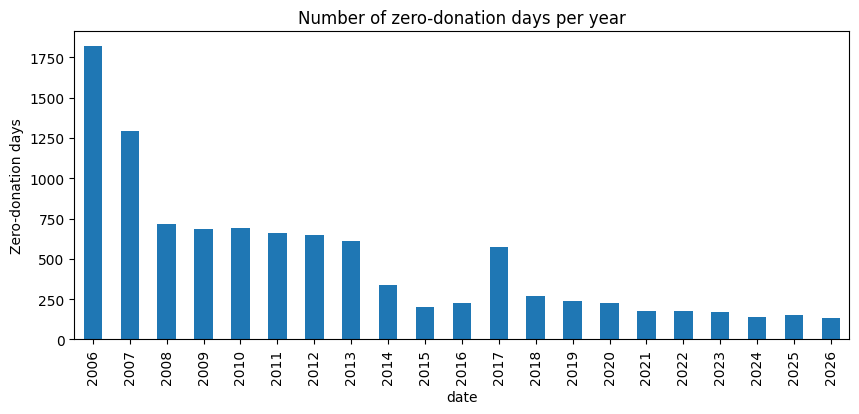

In [151]:
zero_days['date'].dt.year.value_counts().sort_index().plot(kind='bar', figsize=(10,4))
plt.title("Number of zero-donation days per year")
plt.ylabel("Zero-donation days")
plt.show()

In [152]:
start_date = '2015-01-01'
rows_before = len(df)
df = df[df['date'] >= start_date].copy()
print("Rows:", rows_before, "->", len(df))
print("Date range:", df['date'].min().date(), "to", df['date'].max().date())

Rows: 98878 -> 56147
Date range: 2015-01-01 to 2026-10-28


In [153]:
# Every state should have every day in the date range (no missing days)
all_days = pd.date_range(df['date'].min(), df['date'].max())
print("Days in range:", len(all_days))
df.groupby('state', observed=True)['date'].nunique()

Days in range: 4319


,date
state,
Johor,4319
Kedah,4319
Kelantan,4319
Melaka,4319
Negeri Sembilan,4319
Pahang,4319
Perak,4319
Pulau Pinang,4319
Sabah,4319


In [154]:
q1 = df.groupby('state', observed=True)['daily'].transform(lambda x: x.quantile(0.25))
q3 = df.groupby('state', observed=True)['daily'].transform(lambda x: x.quantile(0.75))
iqr = q3 - q1
df['is_outlier'] = (df['daily'] < q1 - 1.5 * iqr) | (df['daily'] > q3 + 1.5 * iqr)

print("Outlier rows:", df['is_outlier'].sum(), "=", round(df['is_outlier'].mean() * 100, 2), "%")
df.groupby('state', observed=True)['is_outlier'].mean().mul(100).round(2)

Outlier rows: 1888 = 3.36 %


,is_outlier
state,
Johor,4.47
Kedah,3.89
Kelantan,3.73
Melaka,1.18
Negeri Sembilan,1.57
Pahang,2.11
Perak,3.15
Pulau Pinang,3.15
Sabah,5.90


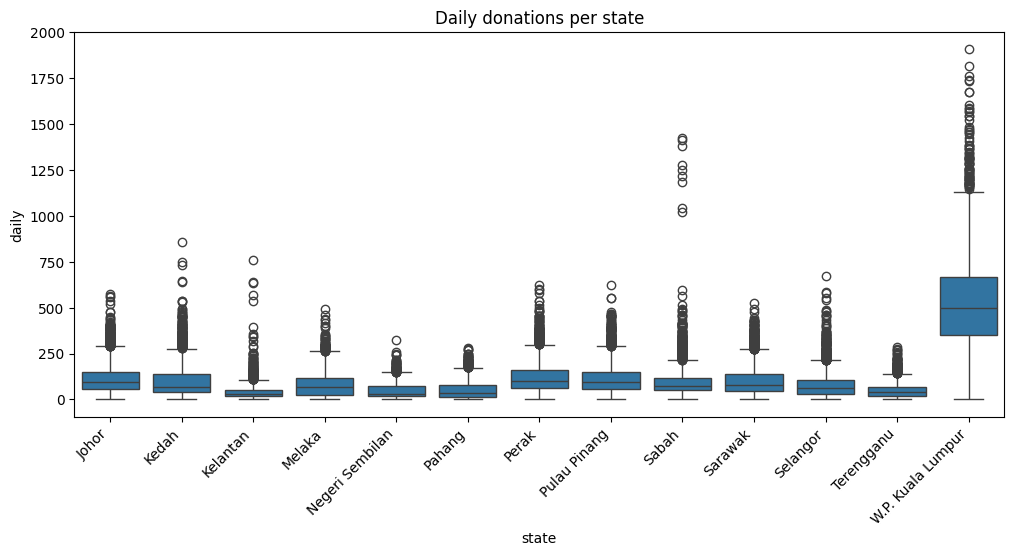

In [155]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df, x='state', y='daily')
plt.xticks(rotation=45, ha='right')
plt.title("Daily donations per state")
plt.show()

In [156]:
# The biggest days
df.sort_values('daily', ascending=False)[['date', 'state', 'daily', 'location_centre', 'location_mobile']].head(10)

,date,state,daily,location_centre,location_mobile
106214,2026-02-01,W.P. Kuala Lumpur,1907,142,1765
102935,2017-02-09,W.P. Kuala Lumpur,1815,66,1749
103381,2018-05-01,W.P. Kuala Lumpur,1763,0,1763
103746,2019-05-01,W.P. Kuala Lumpur,1741,0,1741
103491,2018-08-19,W.P. Kuala Lumpur,1735,79,1656
105859,2025-02-11,W.P. Kuala Lumpur,1677,195,1482
103409,2018-05-29,W.P. Kuala Lumpur,1676,69,1607
103862,2019-08-25,W.P. Kuala Lumpur,1605,103,1502
102553,2016-01-24,W.P. Kuala Lumpur,1588,77,1511
102285,2015-05-01,W.P. Kuala Lumpur,1582,0,1582


In [157]:
df = df.sort_values(['state', 'date']).reset_index(drop=True)

df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day_of_week'] = df['date'].dt.day_of_week
df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)
df['covid_period'] = ((df['date'] >= '2020-03-18') & (df['date'] <= '2022-03-31')).astype(int)

df['lag_1'] = df.groupby('state', observed=True)['daily'].shift(1)
df['lag_7'] = df.groupby('state', observed=True)['daily'].shift(7)
df['rolling_7'] = df.groupby('state', observed=True)['daily'].transform(lambda x: x.shift(1).rolling(7).mean())

# The first 7 days of each state have no history, so they are removed
rows_before = len(df)
df = df.dropna(subset=['lag_1', 'lag_7', 'rolling_7']).reset_index(drop=True)
df['lag_1'] = df['lag_1'].astype('int32')
df['lag_7'] = df['lag_7'].astype('int32')
df['rolling_7'] = df['rolling_7'].astype('float32')
print("Rows:", rows_before, "->", len(df))

# Order by date (needed later for the time-based split)
df = df.sort_values(['date', 'state']).reset_index(drop=True)
df.head()

Rows: 56147 -> 56056


,date,state,daily,blood_a,blood_b,blood_o,blood_ab,location_centre,location_mobile,type_wholeblood,...,blood_unknown,is_outlier,year,month,day_of_week,is_weekend,covid_period,lag_1,lag_7,rolling_7
0,2015-01-08,Johor,59,19,15,22,3,59,0,58,...,0,False,2015,1,3,0,0,153,84,107.285713
1,2015-01-08,Kedah,207,50,71,75,11,207,0,207,...,0,False,2015,1,3,0,0,189,129,149.571426
2,2015-01-08,Kelantan,18,3,3,12,0,18,0,18,...,0,False,2015,1,3,0,0,85,92,68.285713
3,2015-01-08,Melaka,26,7,7,12,0,26,0,24,...,0,False,2015,1,3,0,0,32,69,65.428574
4,2015-01-08,Negeri Sembilan,20,4,6,8,2,20,0,20,...,0,False,2015,1,3,0,0,27,16,34.285713


In [158]:
# [Types of Data, Measurement Level, Units] for every variable
info = {
    'date': ['Datetime', 'Interval', 'Day'],
    'state': ['Categorical', 'Nominal', '-'],
    'year': ['Numeric', 'Interval', 'Year'],
    'month': ['Numeric', 'Ordinal', 'Month (1-12)'],
    'day_of_week': ['Numeric', 'Ordinal', '0=Mon ... 6=Sun'],
    'is_weekend': ['Categorical', 'Nominal', '0/1'],
    'covid_period': ['Categorical', 'Nominal', '0/1'],
    'is_outlier': ['Categorical', 'Nominal', 'True/False'],
    'rolling_7': ['Numeric', 'Ratio', 'Donations per day'],
}
# All the other columns are counts of donations
for col in df.columns:
    if col not in info:
        info[col] = ['Numeric', 'Ratio', 'Donations']

In [159]:
table1 = []
for col in df.columns:
    s = df[col]
    kind, level, unit = info[col]

    if kind == 'Numeric':
        value_range = f"{round(float(s.min()), 2)} - {round(float(s.max()), 2)}"
        min_value = round(float(s.min()), 2)
        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        iqr = q3 - q1
        low = q1 - 1.5 * iqr
        high = q3 + 1.5 * iqr
        n_out = ((s < low) | (s > high)).sum()
        if col == 'daily':
            outliers = f"Yes, {df['is_outlier'].sum()} rows (IQR rule per state)"
        elif n_out > 0 and low <= 0:
            outliers = f"Yes, >{round(high, 1)} ({n_out} rows)"
        elif n_out > 0:
            outliers = f"Yes, <{round(low, 1)} or >{round(high, 1)} ({n_out} rows)"
        else:
            outliers = "No"
    elif kind == 'Datetime':
        value_range = f"{s.min().date()} - {s.max().date()}"
        min_value = s.min().date()
        outliers = "No"
    else:
        value_range = ", ".join(str(v) for v in s.value_counts().index[:3]) + ", etc."
        min_value = "-"
        outliers = "No"

    top_value = s.mode()[0]
    if kind == 'Datetime':
        top_value = top_value.date()

    table1.append({
        'Variable': col,
        'Types of Data': kind,
        'Data Types': str(s.dtype),
        'Measurement Level': level,
        'Units': unit,
        'Range': value_range,
        'Min Value': min_value,
        'Top Value': top_value,
        'Unique Values': s.nunique(),
        'Null Values': s.isnull().sum(),
        'Outliers': outliers,
    })

table1 = pd.DataFrame(table1)
table1

,Variable,Types of Data,Data Types,Measurement Level,Units,Range,Min Value,Top Value,Unique Values,Null Values,Outliers
0,date,Datetime,datetime64[ns],Interval,Day,2015-01-08 - 2026-10-28,2015-01-08,2015-01-08,4312,0,No
1,state,Categorical,category,Nominal,-,"Johor, Kedah, Kelantan, etc.",-,Johor,13,0,No
2,daily,Numeric,int32,Ratio,Donations,0.0 - 1907.0,0.0,0,1109,0,"Yes, 1887 rows (IQR rule per state)"
3,blood_a,Numeric,int32,Ratio,Donations,0.0 - 465.0,0.0,0,353,0,"Yes, >68.0 (5064 rows)"
4,blood_b,Numeric,int32,Ratio,Donations,0.0 - 615.0,0.0,0,357,0,"Yes, >76.5 (4797 rows)"
5,blood_o,Numeric,int32,Ratio,Donations,0.0 - 762.0,0.0,0,552,0,"Yes, >116.5 (5022 rows)"
6,blood_ab,Numeric,int32,Ratio,Donations,0.0 - 129.0,0.0,0,98,0,"Yes, >17.0 (4725 rows)"
7,location_centre,Numeric,int32,Ratio,Donations,0.0 - 1423.0,0.0,0,471,0,"Yes, >149.5 (3701 rows)"
8,location_mobile,Numeric,int32,Ratio,Donations,0.0 - 1765.0,0.0,0,966,0,"Yes, >195.0 (5518 rows)"
9,type_wholeblood,Numeric,int32,Ratio,Donations,0.0 - 1907.0,0.0,0,1108,0,"Yes, >271.5 (4931 rows)"


In [160]:
table2 = []
for col in df.columns:
    s = df[col]
    kind = info[col][0]
    completeness = f"{round(s.notnull().mean() * 100, 1)}%"

    if kind == 'Numeric':
        p25, p50, p75 = s.quantile([0.25, 0.5, 0.75])
        row = {
            'Variable': col,
            'Frequency': '-',
            'Percentile (25th, 50th, 75th)': f"{round(p25, 1)}, {round(p50, 1)}, {round(p75, 1)}",
            'Data Completeness': completeness,
            'Mean': round(s.mean(), 2),
            'Median': round(s.median(), 2),
            'Mode': round(float(s.mode()[0]), 2),
            'Standard Deviation': round(s.std(), 2),
            'Variance': round(s.var(), 2),
            'Skewness': round(s.skew(), 2),
            'Kurtosis': round(s.kurt(), 2),
        }
    elif kind == 'Datetime':
        p25, p50, p75 = s.quantile([0.25, 0.5, 0.75])
        row = {
            'Variable': col,
            'Frequency': '-',
            'Percentile (25th, 50th, 75th)': f"{p25.date()}, {p50.date()}, {p75.date()}",
            'Data Completeness': completeness,
            'Mean': '-', 'Median': s.median().date(), 'Mode': s.mode()[0].date(),
            'Standard Deviation': '-', 'Variance': '-', 'Skewness': '-', 'Kurtosis': '-',
        }
    else:
        top3 = s.value_counts(normalize=True).head(3)
        frequency = ", ".join(f"{k}: {round(v * 100, 1)}%" for k, v in top3.items())
        row = {
            'Variable': col,
            'Frequency': frequency,
            'Percentile (25th, 50th, 75th)': '-',
            'Data Completeness': completeness,
            'Mean': '-', 'Median': '-', 'Mode': s.mode()[0],
            'Standard Deviation': '-', 'Variance': '-', 'Skewness': '-', 'Kurtosis': '-',
        }
    table2.append(row)

table2 = pd.DataFrame(table2)
table2

,Variable,Frequency,"Percentile (25th, 50th, 75th)",Data Completeness,Mean,Median,Mode,Standard Deviation,Variance,Skewness,Kurtosis
0,date,-,"2017-12-20, 2020-12-02, 2023-11-15",100.0%,-,2020-12-02,2015-01-08,-,-,-,-
1,state,"Johor: 7.7%, Kedah: 7.7%, Kelantan: 7.7%",-,100.0%,-,-,Johor,-,-,-,-
2,daily,-,"34.0, 69.0, 130.0",100.0%,116.3,69.0,0.0,154.29,23806.84,3.42,15.49
3,blood_a,-,"8.0, 17.0, 32.0",100.0%,28.79,17.0,0.0,39.12,1530.73,3.42,15.43
4,blood_b,-,"9.0, 19.0, 36.0",100.0%,31.52,19.0,0.0,42.03,1766.48,3.41,16.09
5,blood_o,-,"14.0, 29.0, 55.0",100.0%,49.1,29.0,0.0,65.65,4309.99,3.47,16.21
6,blood_ab,-,"2.0, 4.0, 8.0",100.0%,6.88,4.0,0.0,9.26,85.81,3.25,14.83
7,location_centre,-,"7.0, 24.0, 64.0",100.0%,46.39,24.0,0.0,61.4,3770.14,3.11,24.45
8,location_mobile,-,"0.0, 19.0, 78.0",100.0%,69.91,19.0,0.0,134.09,17981.17,3.66,18.35
9,type_wholeblood,-,"34.0, 69.0, 129.0",100.0%,114.36,69.0,0.0,151.0,22800.02,3.46,16.2


In [161]:
# Save both tables (open in Excel, copy into the Word report)
table1.to_csv(folder + 'table1_data_properties.csv', index=False)
table2.to_csv(folder + 'table2_statistics.csv', index=False)

# Save the cleaned dataset
df.to_csv(folder + 'donations_clean.csv', index=False)
print("Saved to", folder)

Saved to /content/drive/MyDrive/data science project


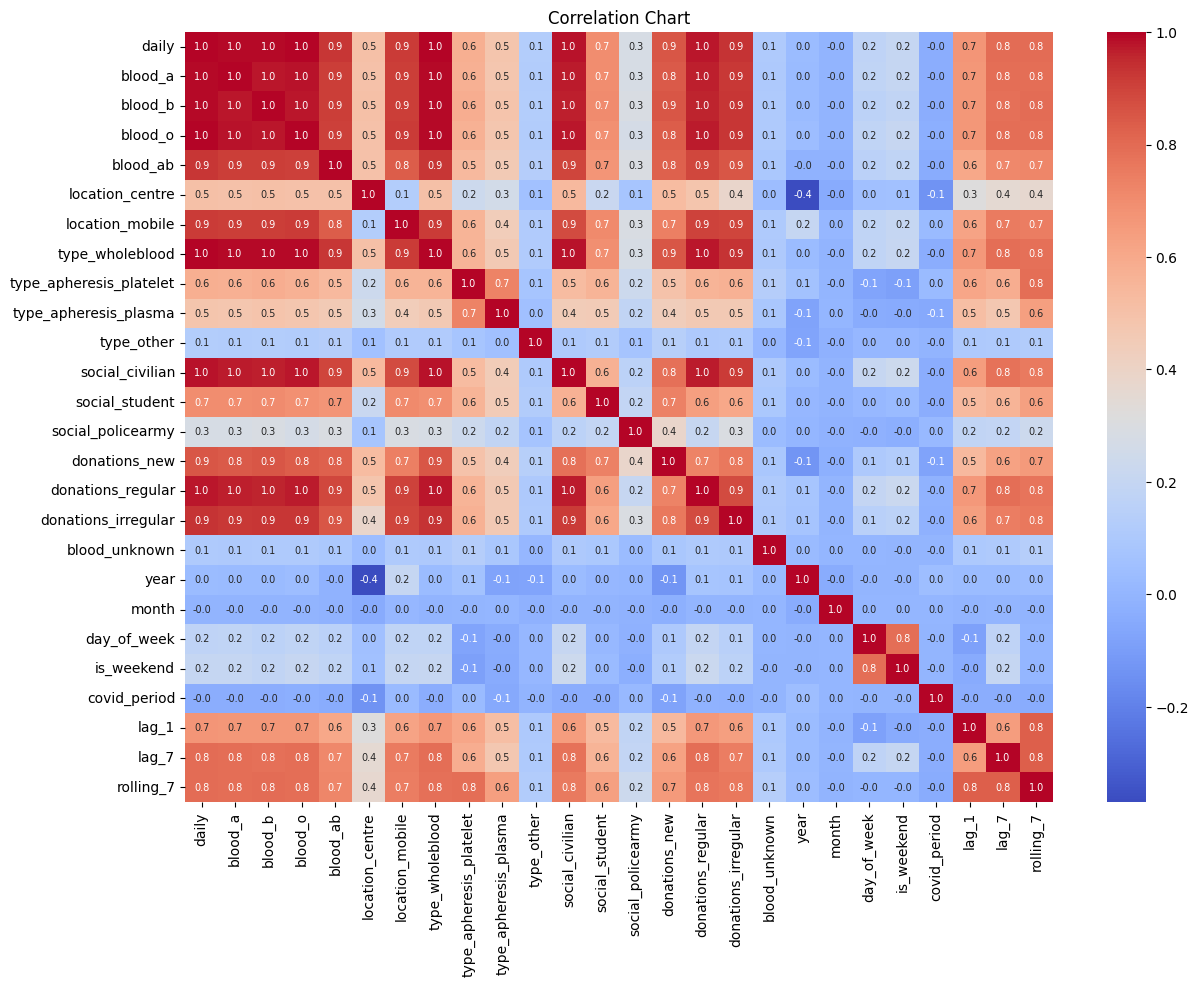

In [162]:
corr = df.select_dtypes('number').corr()
plt.figure(figsize=(14,10))
sns.heatmap(corr, annot=True, fmt='.1f', cmap='coolwarm', annot_kws={'size': 7})
plt.title("Correlation Chart")
plt.show()

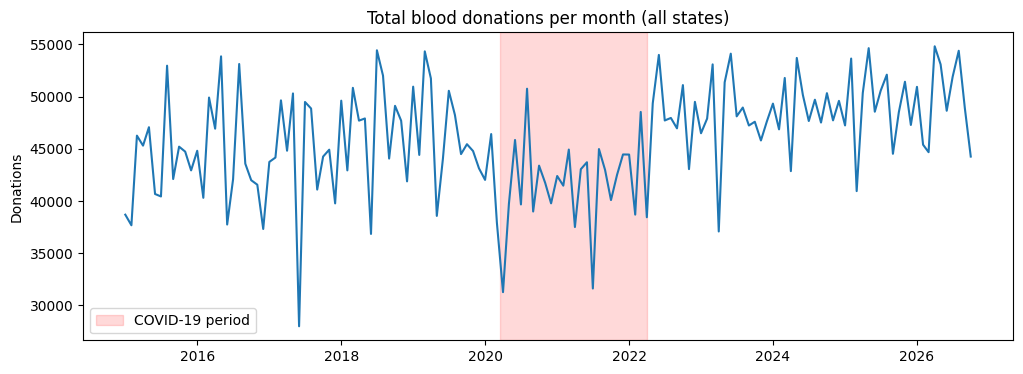

In [163]:
monthly = df.groupby(df['date'].dt.to_period('M'))['daily'].sum()
monthly.index = monthly.index.to_timestamp()

plt.figure(figsize=(12,4))
plt.plot(monthly.index, monthly.values)
plt.axvspan(pd.Timestamp('2020-03-18'), pd.Timestamp('2022-03-31'), color='red', alpha=0.15, label='COVID-19 period')
plt.title("Total blood donations per month (all states)")
plt.ylabel("Donations")
plt.legend()
plt.show()

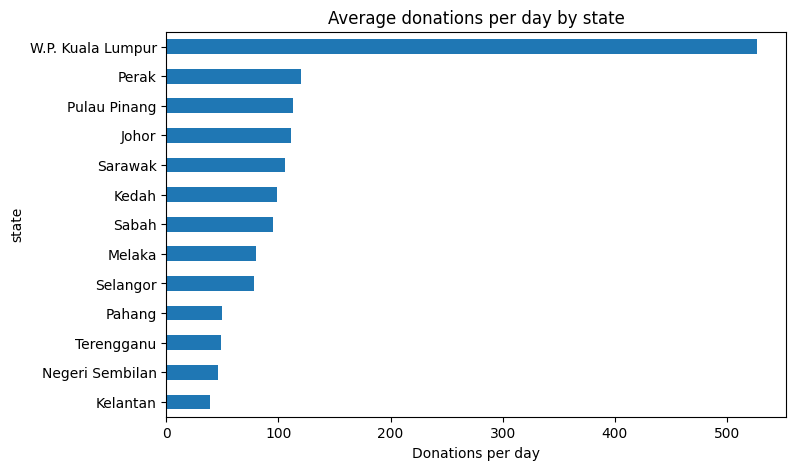

In [164]:
state_avg = df.groupby('state', observed=True)['daily'].mean().sort_values()
state_avg.plot(kind='barh', figsize=(8,5))
plt.title("Average donations per day by state")
plt.xlabel("Donations per day")
plt.show()

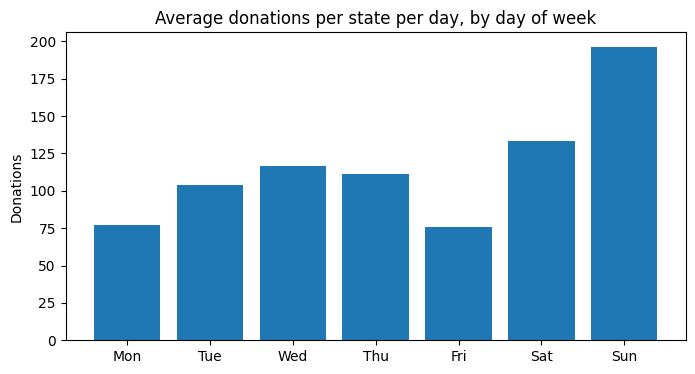

In [165]:
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
by_day = df.groupby('day_of_week')['daily'].mean()

plt.figure(figsize=(8,4))
plt.bar(days, by_day.values)
plt.title("Average donations per state per day, by day of week")
plt.ylabel("Donations")
plt.show()

blood_a     24.8
blood_b     27.1
blood_o     42.2
blood_ab     5.9
dtype: float64


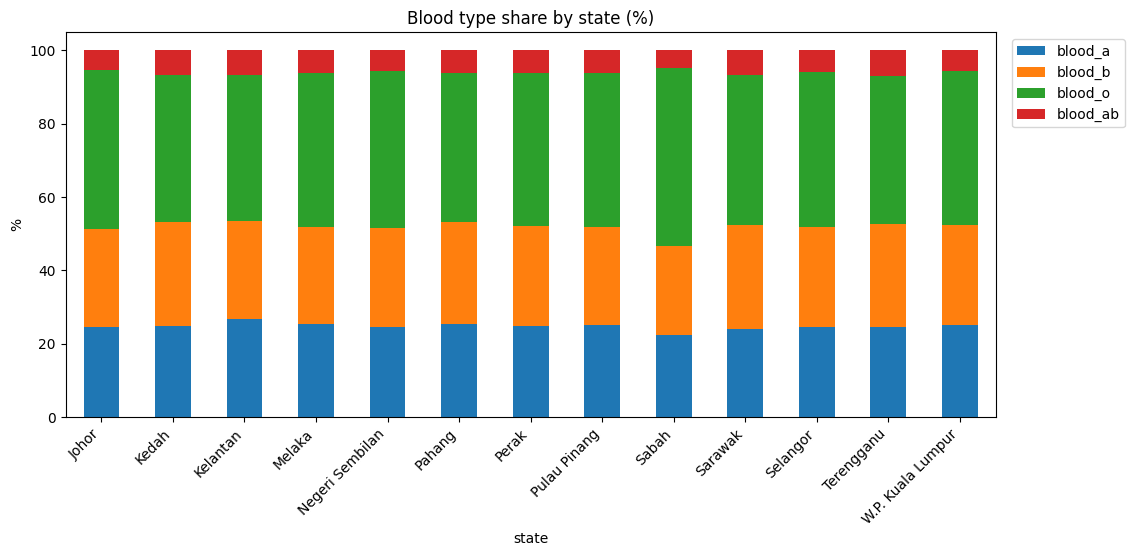

In [166]:
blood_cols = ['blood_a', 'blood_b', 'blood_o', 'blood_ab']
total_blood = df[blood_cols].sum()
print((total_blood / total_blood.sum() * 100).round(1))

state_blood = df.groupby('state', observed=True)[blood_cols].sum()
state_blood_pct = state_blood.div(state_blood.sum(axis=1), axis=0) * 100
state_blood_pct.plot(kind='bar', stacked=True, figsize=(12,5))
plt.title("Blood type share by state (%)")
plt.ylabel("%")
plt.xticks(rotation=45, ha='right')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.show()

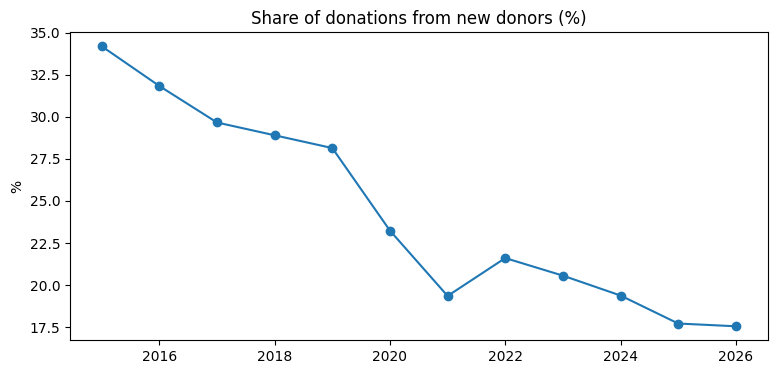

,donations_new,daily,new_donor_%
year,,,
2015,179204,524117,34.191602
2016,169744,533289,31.829646
2017,156942,529124,29.660722
2018,163316,565104,28.900167
2019,157808,560777,28.140954
2020,115606,497590,23.233184
2021,96702,499765,19.349494
2022,120930,559827,21.601316
2023,118285,575403,20.556897


In [167]:
yearly = df.groupby('year')[['donations_new', 'daily']].sum()
yearly['new_donor_%'] = yearly['donations_new'] / yearly['daily'] * 100

plt.figure(figsize=(9,4))
plt.plot(yearly.index, yearly['new_donor_%'], marker='o')
plt.title("Share of donations from new donors (%)")
plt.ylabel("%")
plt.show()
yearly

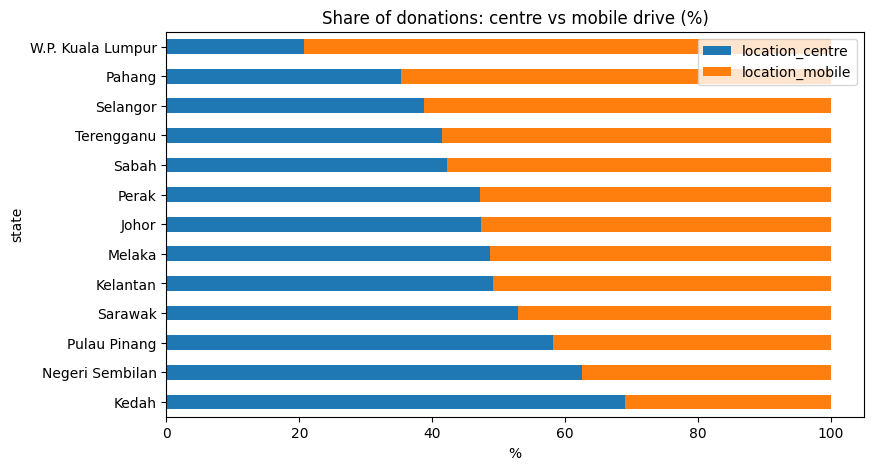

In [168]:
location = df.groupby('state', observed=True)[['location_centre', 'location_mobile']].sum()
location_pct = location.div(location.sum(axis=1), axis=0) * 100
location_pct.sort_values('location_mobile').plot(kind='barh', stacked=True, figsize=(9,5))
plt.title("Share of donations: centre vs mobile drive (%)")
plt.xlabel("%")
plt.show()

In [169]:
features = ['state', 'year', 'month', 'day_of_week', 'is_weekend', 'covid_period', 'lag_1', 'lag_7', 'rolling_7']
target = 'daily'

# One-hot encode state (13 states -> 12 columns of 0/1)
X = pd.get_dummies(df[features], columns=['state'], drop_first=True, dtype=int)
y = df[target]
X.head()

,year,month,day_of_week,is_weekend,covid_period,lag_1,lag_7,rolling_7,state_Kedah,state_Kelantan,state_Melaka,state_Negeri Sembilan,state_Pahang,state_Perak,state_Pulau Pinang,state_Sabah,state_Sarawak,state_Selangor,state_Terengganu,state_W.P. Kuala Lumpur
0,2015,1,3,0,0,153,84,107.285713,0,0,0,0,0,0,0,0,0,0,0,0
1,2015,1,3,0,0,189,129,149.571426,1,0,0,0,0,0,0,0,0,0,0,0
2,2015,1,3,0,0,85,92,68.285713,0,1,0,0,0,0,0,0,0,0,0,0
3,2015,1,3,0,0,32,69,65.428574,0,0,1,0,0,0,0,0,0,0,0,0
4,2015,1,3,0,0,27,16,34.285713,0,0,0,1,0,0,0,0,0,0,0,0


In [170]:
split_date = '2024-01-01'
train = df['date'] < split_date

X_train, X_test = X[train], X[~train]
y_train, y_test = y[train], y[~train]
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (42640, 20)  Test: (13416, 20)


In [171]:
selector = SelectKBest(score_func=f_regression, k='all')
selector.fit(X_train, y_train)

mi = mutual_info_regression(X_train.sample(10000, random_state=42),
                            y_train.sample(10000, random_state=42), random_state=42)

scores = pd.DataFrame({'Feature': X_train.columns,
                       'F-score': selector.scores_.round(1),
                       'Mutual information': mi.round(3)})
scores.sort_values('Mutual information', ascending=False)

,Feature,F-score,Mutual information
6,lag_7,64313.7,0.349
7,rolling_7,67980.2,0.332
5,lag_1,33331.6,0.227
19,state_W.P. Kuala Lumpur,56876.5,0.189
2,day_of_week,1231.1,0.081
3,is_weekend,1593.0,0.038
11,state_Negeri Sembilan,708.7,0.033
12,state_Pahang,736.1,0.032
14,state_Pulau Pinang,1.2,0.027
9,state_Kelantan,977.8,0.025


In [172]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [173]:
def evaluate(name, y_true, y_pred):
    return {'Model': name,
            'MAE': round(mean_absolute_error(y_true, y_pred), 2),
            'RMSE': round(float(np.sqrt(mean_squared_error(y_true, y_pred))), 2),
            'R2': round(r2_score(y_true, y_pred), 3)}

results = []
results.append(evaluate('Baseline (same day last week)', y_test, X_test['lag_7']))
results

[{'Model': 'Baseline (same day last week)',
  'MAE': 53.78,
  'RMSE': 90.09,
  'R2': 0.678}]

In [174]:
models = {
    'Linear Regression': LinearRegression(),
    'KNN': KNeighborsRegressor(n_neighbors=10),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
}

for name, model in models.items():
    if name in ['Linear Regression', 'KNN']:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
    results.append(evaluate(name, y_test, y_pred))
    print(name, "done")

pd.DataFrame(results)

Linear Regression done
KNN done
Decision Tree done
Random Forest done


,Model,MAE,RMSE,R2
0,Baseline (same day last week),53.78,90.09,0.678
1,Linear Regression,48.36,76.40,0.769
2,KNN,41.15,66.97,0.822
3,Decision Tree,59.65,95.68,0.637
4,Random Forest,41.74,67.80,0.818


In [175]:
tscv = TimeSeriesSplit(n_splits=3)

dt_params = {'max_depth': [5, 10, 15, None],
             'min_samples_leaf': [1, 10, 50]}
dt_grid = GridSearchCV(DecisionTreeRegressor(random_state=42), dt_params,
                       cv=tscv, scoring='neg_mean_absolute_error', n_jobs=-1)
dt_grid.fit(X_train, y_train)
print("Best Decision Tree:", dt_grid.best_params_)

Best Decision Tree: {'max_depth': 10, 'min_samples_leaf': 50}


In [176]:
rf_params = {'max_depth': [10, 20],
             'min_samples_leaf': [1, 10]}
rf_grid = GridSearchCV(RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1), rf_params,
                       cv=tscv, scoring='neg_mean_absolute_error', n_jobs=-1)
rf_grid.fit(X_train, y_train)
print("Best Random Forest:", rf_grid.best_params_)

Best Random Forest: {'max_depth': 20, 'min_samples_leaf': 10}


In [177]:
results.append(evaluate('Decision Tree (tuned)', y_test, dt_grid.predict(X_test)))
results.append(evaluate('Random Forest (tuned)', y_test, rf_grid.predict(X_test)))

In [178]:
results_df = pd.DataFrame(results).sort_values('MAE').reset_index(drop=True)
results_df.to_csv(folder + 'model_results.csv', index=False)
results_df

,Model,MAE,RMSE,R2
0,Random Forest (tuned),40.41,66.29,0.826
1,KNN,41.15,66.97,0.822
2,Random Forest,41.74,67.80,0.818
3,Decision Tree (tuned),41.88,67.89,0.817
4,Linear Regression,48.36,76.40,0.769
5,Baseline (same day last week),53.78,90.09,0.678
6,Decision Tree,59.65,95.68,0.637


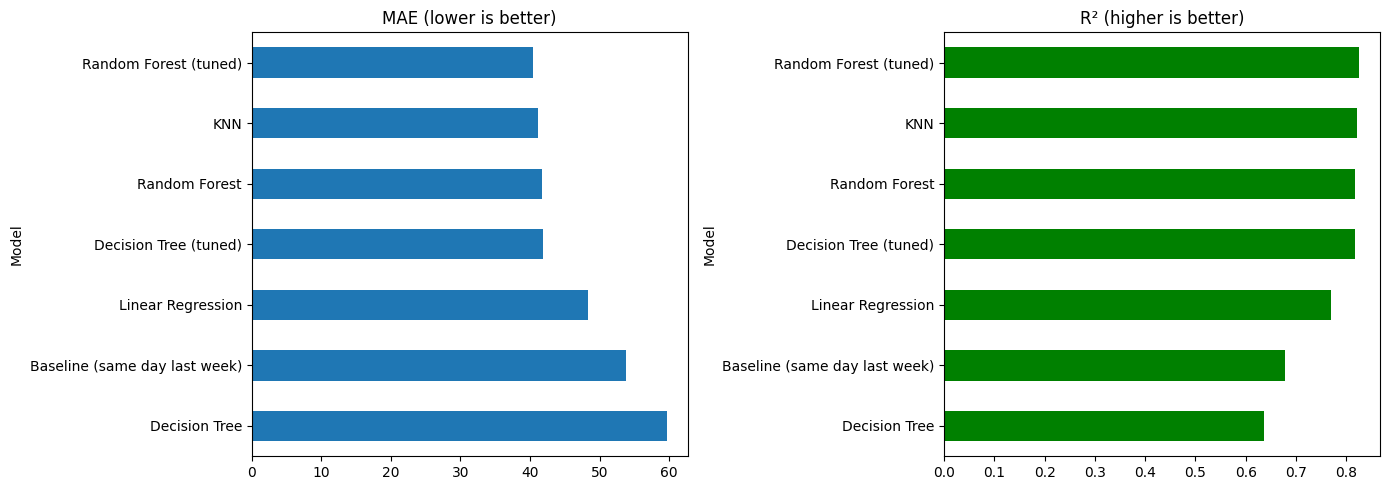

In [179]:
fig, ax = plt.subplots(1, 2, figsize=(14,5))
results_df.plot(x='Model', y='MAE', kind='barh', ax=ax[0], legend=False)
ax[0].set_title("MAE (lower is better)")
ax[0].invert_yaxis()
results_df.plot(x='Model', y='R2', kind='barh', ax=ax[1], legend=False, color='green')
ax[1].set_title("R² (higher is better)")
ax[1].invert_yaxis()
plt.tight_layout()
plt.show()

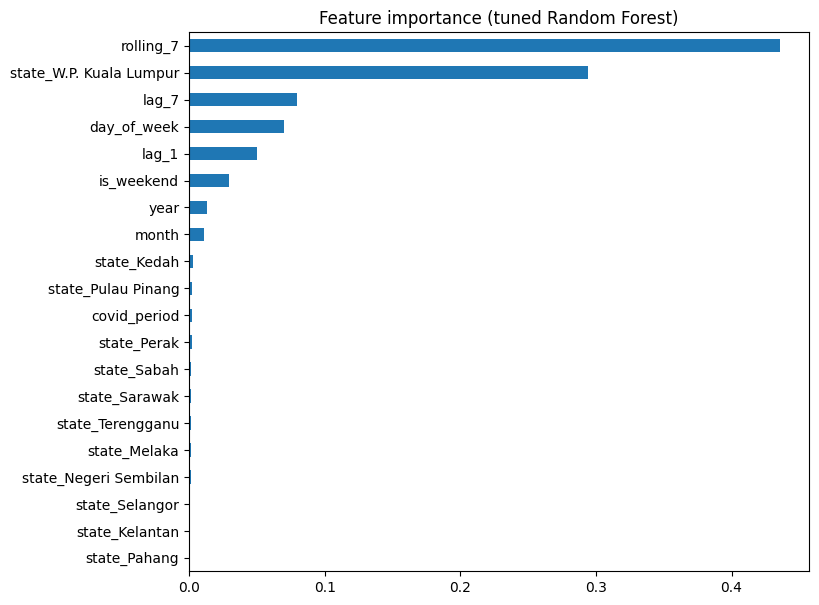

In [180]:
# Which features does the best model use most?
best_rf = rf_grid.best_estimator_
importance = pd.Series(best_rf.feature_importances_, index=X_train.columns).sort_values()
importance.plot(kind='barh', figsize=(8,7))
plt.title("Feature importance (tuned Random Forest)")
plt.show()

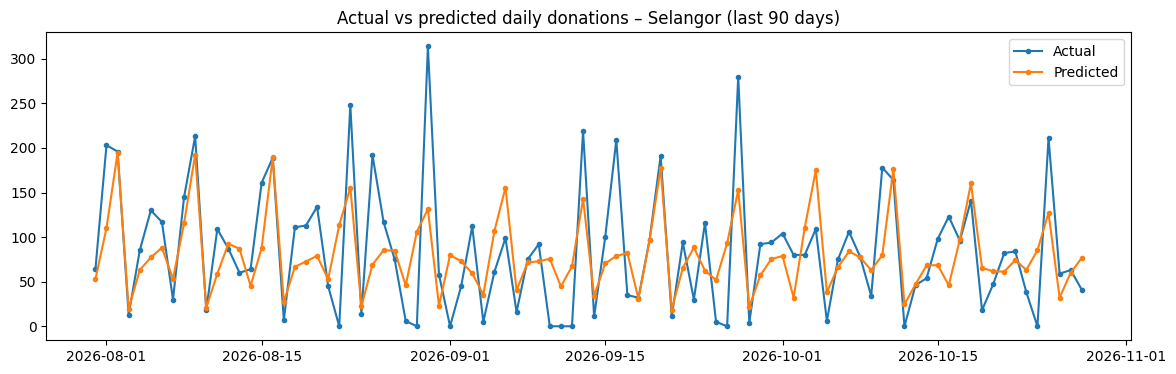

In [181]:
# Actual vs predicted for one state (last 90 days of the test period)
state_name = 'Selangor'
test_rows = df[~train]
mask = (test_rows['state'] == state_name) & (test_rows['date'] > test_rows['date'].max() - pd.Timedelta(days=90))
pred = rf_grid.predict(X_test[mask.values])

plt.figure(figsize=(14,4))
plt.plot(test_rows.loc[mask, 'date'], test_rows.loc[mask, 'daily'], label='Actual', marker='o', markersize=3)
plt.plot(test_rows.loc[mask, 'date'], pred, label='Predicted', marker='o', markersize=3)
plt.title(f"Actual vs predicted daily donations – {state_name} (last 90 days)")
plt.legend()
plt.show()